Optimize model hyperparameters using Bayesian optimization frameworks (Hyperopt, scikit-optimize), balancing exploration and exploitation through acquisition functions and surrogate modeling for accelerated search.

In [13]:
import pandas as pd
import numpy as np

In [14]:
np.random.seed(42)

In [15]:
n_samples = 1500
n_features = 12

In [16]:
X_mat = np.random.normal(0, 1, size=(n_samples, n_features))
feature_cols = [f"icu_biomarker_{i+1}" for i in range(n_features)]

In [17]:
logits = (
    0.65 * X_mat[:, 0]
    - 0.85 * X_mat[:, 1]
    + 0.40 * (X_mat[:, 2] ** 2)
    + 1.10 * X_mat[:, 3] * X_mat[:, 4]  # Non-linear interaction
    - 0.75 * np.sin(X_mat[:, 5])
    + 0.50 * X_mat[:, 6] * X_mat[:, 7]
    - 1.20
)

In [18]:
probs = 1 / (1 + np.exp(-logits))
target = (probs > np.random.uniform(0, 1, n_samples)).astype(int)

In [19]:
df_bayes = pd.DataFrame(X_mat, columns=feature_cols)
df_bayes['icu_readmission'] = target

In [20]:
print("Dataset Shape:", df_bayes.shape)
print("ICU Readmission Target Breakdown:\n", df_bayes['icu_readmission'].value_counts(normalize=True).round(3))

Dataset Shape: (1500, 13)
ICU Readmission Target Breakdown:
 icu_readmission
0    0.638
1    0.362
Name: proportion, dtype: float64


In [21]:
!pip install scikit-optimize

  Using cached scikit_optimize-0.10.2-py2.py3-none-any.whl.metadata (9.7 kB)
Using cached scikit_optimize-0.10.2-py2.py3-none-any.whl (107 kB)



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: C:\Python312\python.exe -m pip install --upgrade pip


In [23]:
import time
import matplotlib.pyplot as plt

In [25]:
from scipy.stats import loguniform, randint
from sklearn.experimental import enable_halving_search_cv  
from sklearn.model_selection import StratifiedKFold, HalvingRandomSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier

In [27]:
X = df_bayes.drop(columns=['icu_readmission'])
y = df_bayes['icu_readmission']

In [28]:
preprocessor = ColumnTransformer(
    transformers=[('scaler', StandardScaler(), feature_cols)]
)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(random_state=42))
])

In [29]:
param_distributions = {
    'classifier__learning_rate': loguniform(0.005, 0.2),
    'classifier__max_iter': randint(80, 250),
    'classifier__max_leaf_nodes': randint(15, 63),
    'classifier__min_samples_leaf': randint(10, 50),
    'classifier__l2_regularization': loguniform(1e-3, 10.0)
}

In [30]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [31]:
bayes_halving = HalvingRandomSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    scoring='f1',
    cv=cv_strategy,
    factor=3,
    resource='n_samples',
    max_resources='auto',
    random_state=42,
    n_jobs=1
)

In [32]:
t0 = time.perf_counter()
bayes_halving.fit(X, y)
t1 = time.perf_counter()

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

In [33]:
print("--- Successive Halving Probabilistic Search Summary ---")
print(f"Total Optimization Time    : {(t1 - t0):.2f} seconds")
print(f"Best F1-Score (CV)         : {bayes_halving.best_score_:.4f}")
print("\nOptimal Parameter Set:")
for param, val in bayes_halving.best_params_.items():
    clean_key = param.replace('classifier__', '')
    if isinstance(val, float):
        print(f"  • {clean_key}: {val:.5f}")
    else:
        print(f"  • {clean_key}: {val}")

--- Successive Halving Probabilistic Search Summary ---
Total Optimization Time    : 48.62 seconds
Best F1-Score (CV)         : 0.4987

Optimal Parameter Set:
  • l2_regularization: 0.00118
  • learning_rate: 0.03092
  • max_iter: 127
  • max_leaf_nodes: 34
  • min_samples_leaf: 17


In [34]:
cv_results = pd.DataFrame(bayes_halving.cv_results_)

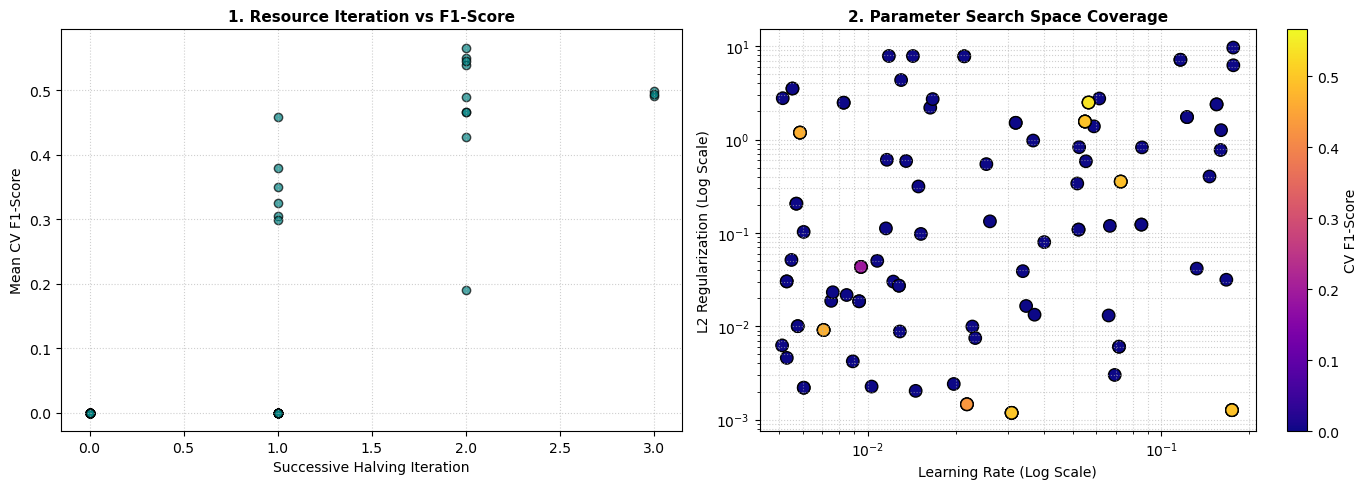

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

iterations = cv_results['iter']
scores = cv_results['mean_test_score']

axes[0].scatter(iterations, scores, color='teal', alpha=0.7, edgecolors='k')
axes[0].set_title("1. Resource Iteration vs F1-Score", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Successive Halving Iteration")
axes[0].set_ylabel("Mean CV F1-Score")
axes[0].grid(True, linestyle=':', alpha=0.6)

lr = cv_results['param_classifier__learning_rate'].astype(float)
l2 = cv_results['param_classifier__l2_regularization'].astype(float)

scatter = axes[1].scatter(lr, l2, c=scores, cmap='plasma', s=80, edgecolors='k')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title("2. Parameter Search Space Coverage", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Learning Rate (Log Scale)")
axes[1].set_ylabel("L2 Regularization (Log Scale)")
axes[1].grid(True, linestyle=':', alpha=0.6, which='both')

fig.colorbar(scatter, ax=axes[1], label="CV F1-Score")
plt.tight_layout()
plt.show()